In [1]:
print("Homework Week-3")

Homework Week-3


In [63]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [3]:
# Load the dataset

data = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [72]:
df = data.copy()

In [73]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [74]:
df.describe()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
mean,54533.212049,2.089400,4.472600,0.494767,0.576600
std,21245.661710,1.188987,2.435906,0.199431,0.494147
min,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,71252.500000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [75]:
df.describe

<bound method NDFrame.describe of          lead_source       industry employment_status       location  \
0     organic_search     technology          employed         europe   
1       social_media     technology          employed  south_america   
2           referral         retail          employed         europe   
3           paid_ads  manufacturing           student            NaN   
4           referral  manufacturing           student  north_america   
...              ...            ...               ...            ...   
4995  organic_search      education          employed           asia   
4996             NaN     technology          employed  north_america   
4997  organic_search        finance          employed           asia   
4998        referral     technology          employed         africa   
4999        referral     technology          employed         europe   

      annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0           88160.0  

<Axes: xlabel='lead_score', ylabel='Count'>

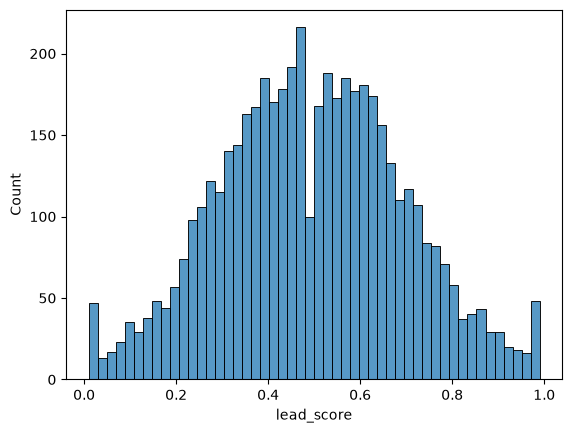

In [76]:
sns.histplot(df.lead_score, bins=50)

<Axes: xlabel='converted', ylabel='Count'>

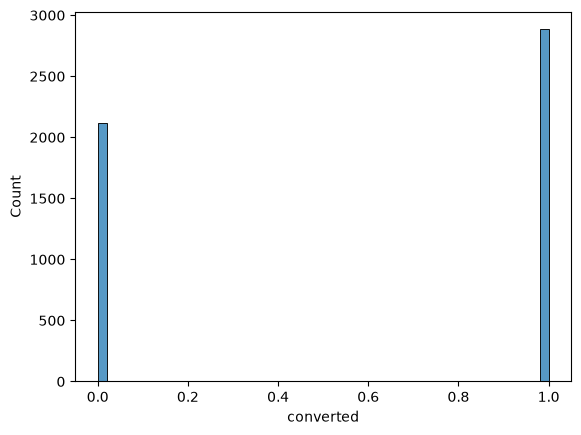

In [9]:
sns.histplot(df.converted, bins=50)

In [77]:
df.columns

Index(['lead_source', 'industry', 'employment_status', 'location',
       'annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted'],
      dtype='str')

In [11]:
print(df.dtypes)

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object


In [17]:
# Data preparation

# Check if the missing values are presented in the features.
# If there are missing values:
# 1. For categorical features, replace them with 'NA'
# 2. For numerical features, replace with with 0.0

In [78]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [79]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [80]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']

In [81]:
df[numerical].isnull().sum()

annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
dtype: int64

In [82]:
df[numerical] = df[numerical].fillna(0.0)

In [83]:
df[numerical].isnull().sum()

annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
dtype: int64

In [84]:
df.annual_income.head()

0    88160.0
1    72688.0
2    44697.0
3        0.0
4    24062.0
Name: annual_income, dtype: float64

In [85]:
df.annual_income.head()

0    88160.0
1    72688.0
2    44697.0
3        0.0
4    24062.0
Name: annual_income, dtype: float64

In [86]:
df.number_of_courses_viewed

0       3
1       3
2       3
3       3
4       4
       ..
4995    2
4996    2
4997    4
4998    4
4999    6
Name: number_of_courses_viewed, Length: 5000, dtype: int64

In [87]:
df[categorical].isnull().sum()

lead_source          148
industry             240
employment_status    194
location             208
dtype: int64

In [88]:
df[categorical] = df[categorical].fillna('NA')

In [89]:
df[categorical].isnull().sum()

lead_source          0
industry             0
employment_status    0
location             0
dtype: int64

In [90]:
df.lead_source.head(10)

0    organic_search
1      social_media
2          referral
3          paid_ads
4          referral
5          referral
6                NA
7          paid_ads
8    organic_search
9          referral
Name: lead_source, dtype: str

In [91]:
df.industry.unique()

<StringArray>
[   'technology',        'retail', 'manufacturing',     'education',
    'healthcare',            'NA',       'finance']
Length: 7, dtype: str

In [92]:
df.industry.mode()

0    technology
Name: industry, dtype: str

In [35]:
# Question 2
# Create the correlation matrix for the numerical features of your dataset. 
# In a correlation matrix, you compute the correlation coefficient between every pair of features.

# What are the two features that have the biggest correlation?

# 1. interaction_count and lead_score
# 2. number_of_courses_viewed and lead_score
# 3. number_of_courses_viewed and interaction_count
# 4. annual_income and interaction_count


In [36]:
# 1. interaction_count and lead_score

df['interaction_count'].corr(df['lead_score'])

np.float64(0.9157457980418671)

In [37]:
# 2. number_of_courses_viewed and lead_score

df['number_of_courses_viewed'].corr(df['lead_score'])

np.float64(0.7572042392104883)

In [38]:
# 3. number_of_courses_viewed and interaction_count

df['number_of_courses_viewed'].corr(df['interaction_count'])

np.float64(0.7216090038937013)

In [39]:
# 4. annual_income and interaction_count

df['annual_income'].corr(df['interaction_count'])

np.float64(0.1228423513595595)

In [40]:
# Correlation matrix heatmap visualization 

--- Correlation Matrix Table ---
                          annual_income  number_of_courses_viewed  \
annual_income                  1.000000                  0.161300   
number_of_courses_viewed       0.161300                  1.000000   
interaction_count              0.122842                  0.721609   
lead_score                     0.229496                  0.757204   

                          interaction_count  lead_score  
annual_income                      0.122842    0.229496  
number_of_courses_viewed           0.721609    0.757204  
interaction_count                  1.000000    0.915746  
lead_score                         0.915746    1.000000  


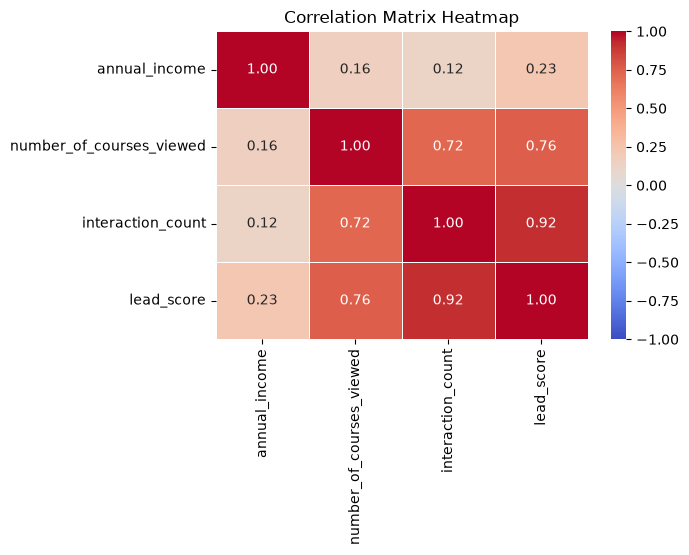

In [41]:
corr_matrix = df[numerical].corr()
print("--- Correlation Matrix Table ---")
print(corr_matrix)

# 4. Visualize with a Seaborn Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(
    corr_matrix,
    annot=True,  # Shows the numbers inside each cell
    cmap="coolwarm",  # Color gradient (blue for negative, red for positive)
    vmin=-1,
    vmax=1,  # Anchors the scale from -1 to 1
    fmt=".2f",  # Formats numbers to 2 decimal places
    linewidths=0.5,  # Adds space between the cells
)

plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
# Question 3

# Calculate the mutual information score between converted and 
# other categorical variables in the dataset. Use the training set only.

# Round the scores to 2 decimals using round(score, 2).

In [93]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [94]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

In [95]:
len(df_full_train), len(df_train), len(df_val), len(df_test)

(4000, 3000, 1000, 1000)

In [96]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [97]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [98]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [99]:
df_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,paid_ads,finance,employed,asia,65980.0,2,3,0.37
1,events,finance,employed,south_america,71662.0,0,0,0.09
2,referral,NA,employed,asia,40220.0,2,5,0.55
3,organic_search,finance,employed,north_america,88352.0,2,2,0.45
4,events,technology,employed,north_america,89316.0,1,5,0.00


In [100]:
df_full_train = df_full_train.reset_index(drop=True)

In [53]:
df_full_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,events,healthcare,employed,south_america,47301.0,5,7,0.69,0
1,organic_search,technology,unemployed,asia,0.0,1,5,0.57,0
2,events,finance,unemployed,asia,47970.0,0,0,0.17,0
3,organic_search,retail,self_employed,south_america,52847.0,3,3,0.45,0
4,paid_ads,finance,employed,africa,73460.0,1,4,0.42,1


In [101]:
df_full_train.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [59]:
# calculating MI (Mutual Information) to all categorical variables

def mutual_info_converted_score(series):
    return round(mutual_info_score(series, df_full_train.converted), 2)

In [60]:
mi = df_full_train[categorical].apply(mutual_info_converted_score)

mi.sort_values(ascending=False)

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

In [ ]:
def mutual_info_converted_score(series):
    return round(mutual_info_score(series, df_full_train.converted), 2)

In [62]:
# Question 4

# Now let's train a logistic regression.

# Remember that we have several categorical variables in the dataset. 
# Include them using one-hot encoding.

# Fit the model on the training dataset.
# 1. To make sure the results are reproducible across different versions of Scikit-Learn, 
# fit the model with these parameters:
# 2. model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

# Calculate the accuracy on the validation dataset and round it to 2 decimal digits.

In [66]:
# Encoding the training set

In [102]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [103]:
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [104]:
# Encoding the validation set

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [105]:
X_train.shape

(3000, 28)

In [106]:
X_val.shape

(1000, 28)

In [107]:
# Training logistic regression with Scikit-Learn

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [108]:
model.predict(X_val)

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,

In [109]:
y_pred = model.predict_proba(X_val)[:, 1]

y_pred

array([0.61725691, 0.44364108, 0.60433996, 0.64562246, 0.52214159,
       0.77885722, 0.60698076, 0.54481903, 0.76770971, 0.52765495,
       0.75038798, 0.6470054 , 0.56857815, 0.51044645, 0.59921425,
       0.46620745, 0.62786484, 0.69167143, 0.69082953, 0.59101344,
       0.49964695, 0.55590822, 0.65303933, 0.6079306 , 0.7231576 ,
       0.51616805, 0.56141276, 0.57206269, 0.67043904, 0.55599224,
       0.63613322, 0.70337215, 0.45463513, 0.61897288, 0.65250689,
       0.42775649, 0.63943096, 0.62315373, 0.6602988 , 0.51736304,
       0.53774147, 0.76074014, 0.48326071, 0.74151288, 0.63662375,
       0.41194601, 0.45371292, 0.6417333 , 0.43851314, 0.87060984,
       0.72468973, 0.75643941, 0.5296636 , 0.66736678, 0.50444495,
       0.57644782, 0.72318139, 0.72497254, 0.6507741 , 0.628958  ,
       0.7217776 , 0.59231588, 0.70824617, 0.61451576, 0.49691434,
       0.74445314, 0.52773381, 0.61402574, 0.55979831, 0.59024431,
       0.69368703, 0.72962242, 0.76111566, 0.60744404, 0.52501

In [110]:
# Calculating the Accuracy

converted_decision = (y_pred >= 0.5)
converted_decision

array([ True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False,  True,  True,
        True,  True, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True, False,
        True,  True,  True,  True,  True,  True, False,  True,  True,
       False, False,  True, False,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False, False,

In [111]:
accuracy_score = (y_val == converted_decision).mean()

round(accuracy_score, 2)

np.float64(0.64)

In [113]:
accuracy_score

np.float64(0.645)

In [112]:
# Question 5

# Let's find the least useful feature using the feature elimination technique.

# Train a model using the same features and parameters as in Q4 (without rounding).

# Now exclude each feature from this set and train a model without it. 
# Record the accuracy for each model.

# For each feature, calculate the difference between the original accuracy 
# and the accuracy without the feature.

In [114]:
# Train data set with out - lead_source

X_small_1 = ['industry', 'employment_status', 'location']

train_dict = df_train[X_small_1 + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [115]:
dv.get_feature_names_out

<bound method DictVectorizer.get_feature_names_out of DictVectorizer(sparse=False)>

In [116]:
# Encoding the validation set

val_dict = df_val[X_small_1 + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [117]:
X_train.shape

(3000, 22)

In [118]:
X_val.shape

(1000, 22)

In [119]:
# Training logistic regression with Scikit-Learn

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [120]:
model.predict(X_val)

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,

In [121]:
y_pred = model.predict_proba(X_val)[:, 1]

y_pred

array([0.61638735, 0.44345856, 0.6075418 , 0.64360473, 0.52392326,
       0.77842935, 0.60509014, 0.54347541, 0.76740648, 0.52864813,
       0.75069027, 0.64546231, 0.57140156, 0.51060911, 0.59635991,
       0.46770881, 0.63073768, 0.69028429, 0.68932654, 0.58896021,
       0.50179616, 0.55866147, 0.65420248, 0.61045716, 0.72196037,
       0.51635293, 0.56189393, 0.56968689, 0.67158396, 0.55606568,
       0.63439585, 0.70476695, 0.4550778 , 0.61711093, 0.65448585,
       0.4284077 , 0.64234797, 0.62114094, 0.66357679, 0.51292415,
       0.53823082, 0.7606954 , 0.48424703, 0.74200787, 0.63575888,
       0.41277115, 0.45515769, 0.64452084, 0.43749397, 0.87157603,
       0.72401797, 0.75599199, 0.52961287, 0.67061147, 0.50644917,
       0.57809045, 0.72714832, 0.72444111, 0.65128022, 0.63138688,
       0.72628969, 0.59074336, 0.70679226, 0.61820244, 0.49890602,
       0.743399  , 0.53044591, 0.61673361, 0.56345747, 0.59020869,
       0.69261748, 0.73172117, 0.76026526, 0.6086622 , 0.52472

In [122]:
# Calculating the Accuracy

converted_decision = (y_pred >= 0.5)
converted_decision

array([ True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True, False,
        True,  True,  True,  True,  True,  True, False,  True,  True,
       False, False,  True, False,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False, False,

In [123]:
accuracy_score = (y_val == converted_decision).mean()

accuracy_score

np.float64(0.642)

In [124]:
# Train data set with out - number_of_courses_viewed

X_small_2 = ['annual_income', 'interaction_count', 'lead_score']

train_dict = df_train[categorical + X_small_2].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [125]:
# Encoding the validation set

val_dict = df_val[categorical + X_small_2].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [126]:
# Training logistic regression with Scikit-Learn

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [127]:
model.predict(X_val)

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,

In [128]:
y_pred = model.predict_proba(X_val)[:, 1]

y_pred

array([0.61188562, 0.46625195, 0.59932784, 0.65340899, 0.53691801,
       0.75715947, 0.60389614, 0.5338574 , 0.75639588, 0.51977425,
       0.72517473, 0.63493854, 0.56273801, 0.49673877, 0.60835435,
       0.47354039, 0.61795727, 0.68857655, 0.69594751, 0.58023101,
       0.51897114, 0.56297873, 0.66631564, 0.61340027, 0.71334221,
       0.53217327, 0.56786372, 0.57573638, 0.66129367, 0.5530571 ,
       0.64491516, 0.69676482, 0.47498363, 0.61209788, 0.6272799 ,
       0.45345348, 0.62650464, 0.62564319, 0.66269817, 0.52474473,
       0.53928676, 0.76505778, 0.49713558, 0.73403341, 0.60559895,
       0.4314803 , 0.47354337, 0.64869595, 0.44180345, 0.85271496,
       0.73072585, 0.75518103, 0.52307708, 0.65826189, 0.5124175 ,
       0.59880872, 0.71040019, 0.70565299, 0.6471451 , 0.63919902,
       0.70053271, 0.58114804, 0.71021751, 0.61776669, 0.51797928,
       0.72169825, 0.53003503, 0.61785375, 0.55430823, 0.60973308,
       0.69873281, 0.71704339, 0.751397  , 0.61198058, 0.54970

In [129]:
# Calculating the Accuracy

converted_decision = (y_pred >= 0.5)
converted_decision

array([ True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True, False,  True, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True, False,
        True,  True,  True,  True,  True,  True, False,  True,  True,
       False, False,  True, False,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False, False,

In [130]:
accuracy_score_2 = (y_val == converted_decision).mean()

accuracy_score_2

np.float64(0.643)

In [131]:
# Train data set with out - interaction_count

X_small_3 = ['annual_income', 'number_of_courses_viewed', 'lead_score']

train_dict = df_train[categorical + X_small_3].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [132]:
# Encoding the validation set

val_dict = df_val[categorical + X_small_3].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [133]:
# Training logistic regression with Scikit-Learn

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

In [134]:
model.predict(X_val)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [135]:
y_pred = model.predict_proba(X_val)[:, 1]

y_pred

array([0.63588762, 0.62624455, 0.57554898, 0.6251328 , 0.62970753,
       0.58978376, 0.58436772, 0.5       , 0.59731851, 0.52077774,
       0.52437566, 0.59115788, 0.58481705, 0.56813281, 0.64556389,
       0.61414299, 0.60976404, 0.61829914, 0.59652985, 0.55258471,
       0.59152128, 0.58308628, 0.58443168, 0.62534714, 0.63264843,
       0.57038259, 0.57846998, 0.56142494, 0.59552203, 0.60313181,
       0.56606576, 0.59393024, 0.67564481, 0.56084129, 0.52077774,
       0.64599348, 0.52126543, 0.60609552, 0.59242014, 0.66231666,
       0.56290719, 0.56626661, 0.57159125, 0.5       , 0.5       ,
       0.62426845, 0.60987616, 0.62187601, 0.6049782 , 0.5       ,
       0.5901995 , 0.60009732, 0.59514305, 0.59691174, 0.60415979,
       0.5832143 , 0.54806763, 0.57834831, 0.63171543, 0.64190533,
       0.5       , 0.55013342, 0.63901383, 0.54462044, 0.60060111,
       0.61213431, 0.56975586, 0.61556907, 0.52077774, 0.63200559,
       0.59518313, 0.54573392, 0.61168339, 0.55355425, 0.60874

In [136]:
# Calculating the Accuracy

converted_decision = (y_pred >= 0.5)
converted_decision

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,

In [137]:
accuracy_score_3 = (y_val == converted_decision).mean()

accuracy_score_3

np.float64(0.601)

In [138]:
accuracy_score, accuracy_score_2, accuracy_score_3

(np.float64(0.642), np.float64(0.643), np.float64(0.601))

In [139]:
original_accuracy_score = 0.645

In [141]:
original_accuracy_score - accuracy_score, original_accuracy_score - accuracy_score_2, original_accuracy_score - accuracy_score_3

(np.float64(0.0030000000000000027),
 np.float64(0.0020000000000000018),
 np.float64(0.04400000000000004))

In [143]:
# Question 6

# Now let's train a regularized logistic regression.

# Let's try the following values of the parameter C: [0.000001, 0.00001, 0.0001, 0.001].

# Train models using all the features as in Q4.

# Calculate the accuracy on the validation dataset and round it to 3 decimal digits.

In [147]:
# Feature encoding
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

# Values of C to evaluate
C_values = [0.000001, 0.00001, 0.0001, 0.001]

# Store accuracy for each value of C
scores = {}

for C in C_values:
    # Train the model
    model = LogisticRegression(
        solver='liblinear',
        C=C,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)

    # Predict probabilities for the positive class
    y_pred = model.predict_proba(X_val)[:, 1]

    # Convert probabilities to binary predictions
    y_pred_binary = (y_pred >= 0.5)

    # Calculate accuracy
    accuracy = (y_val == y_pred_binary).mean()

    # Store the result
    scores[C] = round(accuracy, 3)

# Print the results
for C, accuracy in scores.items():
    print(f"C = {C}: accuracy = {accuracy}")

# Select the C with the highest accuracy
best_C = max(scores, key=scores.get)

print(f"\nBest C: {best_C}")
print(f"Best accuracy: {scores[best_C]}")


C = 1e-06: accuracy = 0.598
C = 1e-05: accuracy = 0.598
C = 0.0001: accuracy = 0.613
C = 0.001: accuracy = 0.645

Best C: 0.001
Best accuracy: 0.645
